# Exercício 02 — Redes neurais para classificação

Este notebook reproduz, em Python/NumPy, os experimentos da seção 4.8 de *Machine Learning Methods in Geoscience*:

1. classificação binária semelhante às Figuras 4.13, 4.15, 4.17 e 4.18;
2. validação do gradiente por diferenças finitas, semelhante à Figura 4.26;
3. classificação multiclasse pela quantidade de bits iguais a 1, semelhante ao exemplo da seção 4.4.2 da edição indicada no enunciado.

Os algoritmos foram convertidos dos códigos MATLAB `NNode1.m`, `NNode_test.m` e `NNode_multiclass.m`. A implementação reutilizável está em `neural_network.py`; este notebook concentra a execução, as figuras e a discussão. Fontes: [laboratório multiclasse](http://utam.gg.utah.edu/Classes/ML/LAB1/Chapter.Book.FCN/Chapter.MultiGNN/lab.html) e o livro *Machine Learning Methods in Geoscience* de Gerard T. Schuster.

**Autor: Lucas Torres Marques**

## Conversão e protocolo experimental

A conversão preserva as convenções centrais do MATLAB: exemplos em colunas, bias na primeira coluna de cada matriz de pesos, treinamento em lote completo e pesos iniciais uniformes em $[0,0{,}1)$. A propagação direta é

$$z^{[l]}=W^{[l]}\begin{bmatrix}1\\a^{[l-1]}\end{bmatrix},\qquad a^{[l]}=g(z^{[l]}),$$

e os gradientes são calculados por retropropagação. Na classificação binária, a saída é sigmoide; na multiclasse, é softmax. Para permitir comparações justas, todos os casos binários usam os mesmos dados, sementes fixas e 400 atualizações.

Duas particularidades dos fontes são tratadas explicitamente:

- os gráficos MATLAB dizem “RMS”, mas `gradientnn.m` calcula a média dos erros quadráticos, sem raiz;
- a opção 2 do `activation.m` multiclasse é chamada de ReLU nos textos, mas implementa ELU ($e^z-1$ para $z<0$). A reprodução abaixo a identifica corretamente como ELU.

As acurácias são de treinamento, como no laboratório original. Portanto, demonstram capacidade de ajuste, não generalização para dados inéditos.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Permite executar tanto dentro de exercise02/ quanto a partir da raiz do repositório.
project_dir = Path.cwd()
if not (project_dir / "neural_network.py").exists():
    project_dir = project_dir / "exercise02"
sys.path.insert(0, str(project_dir.resolve()))

from neural_network import (
    binary_accuracy,
    generate_binary_data,
    generate_multiclass_data,
    gradient_check,
    initialize_weights,
    multiclass_accuracy,
    predict,
    train_backtracking,
    train_conjugate_gradient,
)

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 10, "axes.labelsize": 9})
pd.options.display.float_format = "{:.6g}".format
THRESHOLD = 0.34

## 1. Classificação binária

Cada entrada (amostra) é um vetor $x\in\{0,1\}^5$. A classe é $y=1$ somente para $x=(0,0,0,0,0)$; qualquer outro vetor recebe $y=0$. Assim como em `Datain1.m`, o conjunto é balanceado para conter 50 exemplos de cada classe e depois embaralhado.

Por uma questão de reprodutibilidade, vamos sempre utilizar a seed 42 para geração do conjunto de dados.

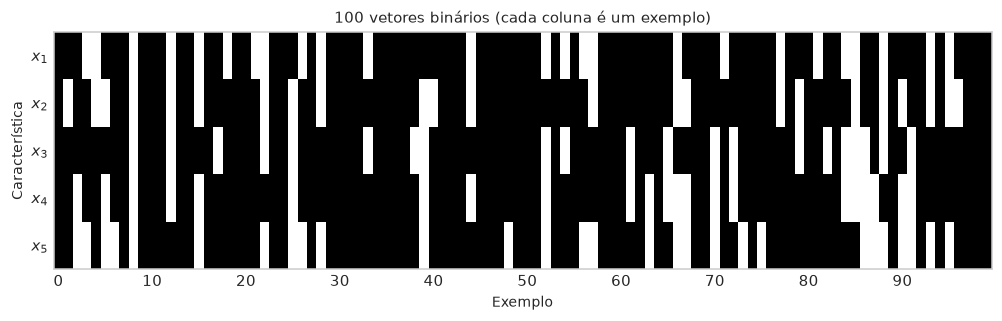

Formato de X: (5, 100); classe 0: 50; classe 1: 50


In [2]:
x_binary, y_binary = generate_binary_data(seed=42)

fig, ax = plt.subplots(figsize=(11, 2.8))
ax.imshow(x_binary, cmap="gray", aspect="auto", interpolation="nearest", vmin=0, vmax=1)
ax.set(title="100 vetores binários (cada coluna é um exemplo)", xlabel="Exemplo", ylabel="Característica")
ax.set_yticks(range(5), [f"$x_{i}$" for i in range(1, 6)])
ax.set_xticks(range(0, 100, 10), [f"{i}" for i in range(0, 100, 10)])
ax.grid(False)
plt.show()

print(f"Formato de X: {x_binary.shape}; classe 0: {int((y_binary == 0).sum())}; classe 1: {int((y_binary == 1).sum())}")

### Configurações das Figuras 4.13, 4.15, 4.17 e 4.18

Para o primeiro caso, isto é, Figura 4.13, é utilizado uma rede "rasa", sem camadas ocultas (`[5, 1]`). Esse tipo de rede funciona justamente como uma regressão logística, pois possui uma única camada de pesos.

Para os outros casos (Fig. 4.15, 4.17 e 4.18), utilizamos a arquitetura `[5, 1, 1]`, com uma camada oculta de um neurônio.

Em todos os casos, vamos definir o limiar de decisão como 0,34, assim como foi usado no código do livro de referência.

In [3]:
binary_configs = {
    "Figura 4.13": {"layers": [5, 1], "loss": "l2", "activation": "sigmoid"},
    "Figura 4.15": {"layers": [5, 1, 1], "loss": "l2", "activation": "sigmoid"},
    "Figura 4.17": {"layers": [5, 1, 1], "loss": "binary_cross_entropy", "activation": "sigmoid"},
    "Figura 4.18": {"layers": [5, 1, 1], "loss": "binary_cross_entropy", "activation": "relu"},
}

binary_results = {}
summary_rows = []
for figure_name, config in binary_configs.items():
    initial_weights = initialize_weights(config["layers"], seed=42)
    result = train_backtracking(
        x_binary,
        y_binary,
        initial_weights,
        hidden_activation=config["activation"],
        output_activation="sigmoid",
        loss_name=config["loss"],
        n_iterations=400,
    )
    probability = predict(
        x_binary, result.weights, config["activation"], "sigmoid"
    )
    binary_results[figure_name] = (result, probability)
    summary_rows.append(
        {
            "Referência": figure_name,
            "Arquitetura": str(config["layers"]),
            "Perda": "L2/MSE" if config["loss"] == "l2" else "Entropia cruzada",
            "Ativação oculta": config["activation"].upper(),
            "Perda inicial": result.losses[0],
            "Perda final": result.losses[-1],
            "Acurácia": binary_accuracy(y_binary, probability, THRESHOLD),
        }
    )

binary_summary = pd.DataFrame(summary_rows)
binary_summary

,Referência,Arquitetura,Perda,Ativação oculta,Perda inicial,Perda final,Acurácia
0,Figura 4.13,"[5, 1]",L2/MSE,SIGMOID,0.270472,0.0155949,1
1,Figura 4.15,"[5, 1, 1]",L2/MSE,SIGMOID,0.251237,0.0169998,1
2,Figura 4.17,"[5, 1, 1]",Entropia cruzada,SIGMOID,0.695627,0.0235558,1
3,Figura 4.18,"[5, 1, 1]",Entropia cruzada,RELU,0.697061,0.0105228,1


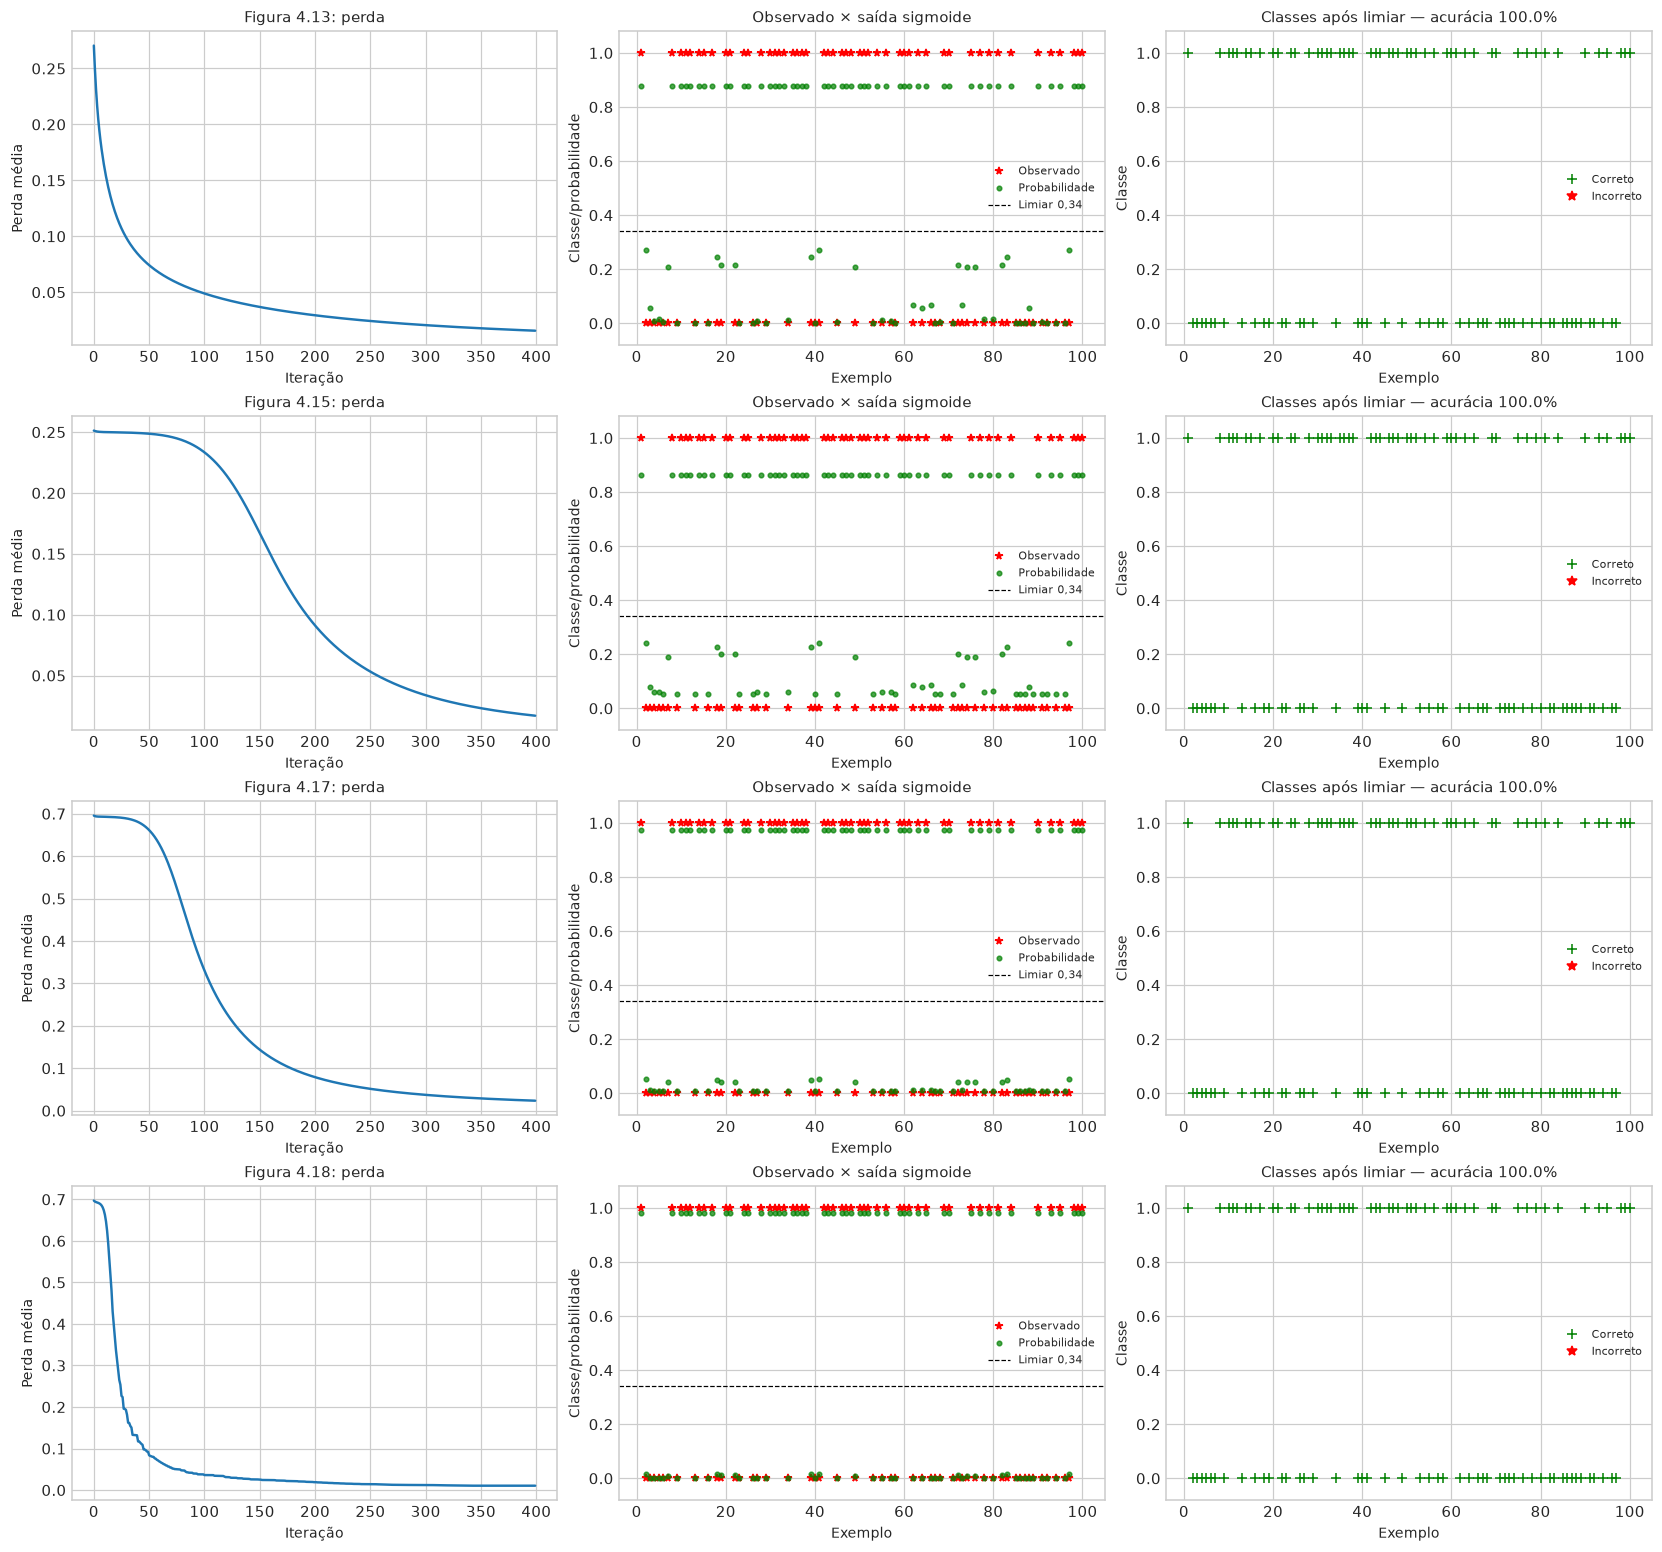

In [4]:
fig, axes = plt.subplots(4, 3, figsize=(15, 14), constrained_layout=True)
examples = np.arange(1, y_binary.size + 1)

for row, (figure_name, config) in enumerate(binary_configs.items()):
    result, probability = binary_results[figure_name]
    predicted_class = (probability >= THRESHOLD).astype(float)

    axes[row, 0].plot(result.losses, color="tab:blue", linewidth=1.6)
    axes[row, 0].set(title=f"{figure_name}: perda", xlabel="Iteração", ylabel="Perda média")

    axes[row, 1].plot(examples, y_binary.ravel(), "r*", label="Observado", markersize=5)
    axes[row, 1].plot(examples, probability.ravel(), "go", label="Probabilidade", markersize=3, alpha=0.7)
    axes[row, 1].axhline(THRESHOLD, color="black", linestyle="--", linewidth=0.8, label="Limiar 0,34")
    axes[row, 1].set(title="Observado × saída sigmoide", xlabel="Exemplo", ylabel="Classe/probabilidade", ylim=(-0.08, 1.08))

    correct = predicted_class.ravel() == y_binary.ravel()

    axes[row, 2].plot(
        examples[correct],
        predicted_class.ravel()[correct],
        "g+",
        label="Correto",
        markersize=7
    )

    axes[row, 2].plot(
        examples[~correct],
        predicted_class.ravel()[~correct],
        "r*",
        label="Incorreto",
        markersize=7
    )

    axes[row, 2].set(
        title=f"Classes após limiar — acurácia {correct.mean():.1%}",
        xlabel="Exemplo",
        ylabel="Classe",
        ylim=(-0.08, 1.08)
    )

for ax in axes[:, 1:].flat:
    ax.legend(loc="center right", fontsize=7)

plt.show()

### Discussão dos resultados binários

Todas as configurações classificam corretamente os 100 exemplos com o limiar do laboratório, mas chegam a esse resultado por superfícies de perda diferentes.

- **Figura 4.13:** a rede `[5, 1]` é suficiente porque o vetor nulo é linearmente separável dos outros vértices do hipercubo binário. A saída contínua não precisa alcançar exatamente 0 ou 1 para que a classificação pelo limiar esteja correta. Apesar de ser a abordagem mais simples, percebe-se que o resultado final (gráfico da direita) foi o mesmo, com uma convergência relativamente rápida (gráfico da esquerda). Entretanto, fica evidente (gráfico do meio) que se fossemos um pouco mais restritivo em nosso limiar de decisão (Ex.: 0,2 ao invés de 0,34), o resultado já mudaria completamente, classificando várias amostrar como classe 1, quando na verdade são da classe 0.

- **Figura 4.15:** ao acrescentar um neurônio oculto, a parametrização aumenta e torna a otimização L2 um pouco mais lenta (gráfico da esquerda); mais profundidade não implica melhora automática neste problema simples. Não só o resultado foi idêntico aos demais, como a rede sofreu do mesmo problema que o regressor logístico: ao diminuir o limiar de decisão, o número de erros aumentaria significativamente (gráfico do meio).

- **Figura 4.17:** a entropia cruzada elimina, da derivada final, o fator de saturação adicional que aparece ao combinar MSE e sigmoide. Isso produz probabilidades mais próximas dos rótulos e uma queda mais decisiva da perda. Neste momento, começamos a obter resultados mais interessantes: convergência rápida (gráfico da esquerda) e maior confiança na classificação (gráfico do meio).

- **Figura 4.18:** a ReLU evita saturação na camada oculta e obtém a menor perda final entre os quatro casos. A busca por bisseção reduz o passo quando uma atualização faria a perda crescer. Dessa forma, esse conjunto de hiperparâmetros foi o que se saiu melhor para esse problema.

Os valores numéricos não precisam coincidir ponto a ponto com o MATLAB porque o gerador aleatório do NumPy é diferente, mas a tendência qualitativa, a tarefa e as arquiteturas são as mesmas.

## 2. Validação do gradiente — Figura 4.26

O `NNode_test.m` compara o gradiente analítico de uma rede `[5, 10, 1]` com diferenças centrais:

$$\left[\frac{\partial\epsilon}{\partial w_{ij}}\right]_{FD}
=\frac{\epsilon(w_{ij}+h)-\epsilon(w_{ij}-h)}{2h},\qquad h=10^{-4}.$$

A diferença de cada camada é normalizada pelo maior módulo do respectivo gradiente analítico, reproduzindo o critério da Figura 4.26. O teste usa entropia cruzada e ReLU, última combinação percorrida pelos laços do MATLAB.

In [5]:
gradient_weights = initialize_weights([5, 10, 1], seed=999)
check = gradient_check(
    x_binary,
    y_binary,
    gradient_weights,
    hidden_activation="relu",
    output_activation="sigmoid",
    loss_name="binary_cross_entropy",
    epsilon=1e-4,
)

gradient_training = train_backtracking(
    x_binary,
    y_binary,
    gradient_weights,
    hidden_activation="relu",
    output_activation="sigmoid",
    loss_name="binary_cross_entropy",
    n_iterations=200,
)

print(f"Maior erro absoluto: {check['max_absolute_error']:.3e}")
print(f"Erro relativo L2:    {check['relative_l2_error']:.3e}")

Maior erro absoluto: 2.532e-11
Erro relativo L2:    9.972e-11


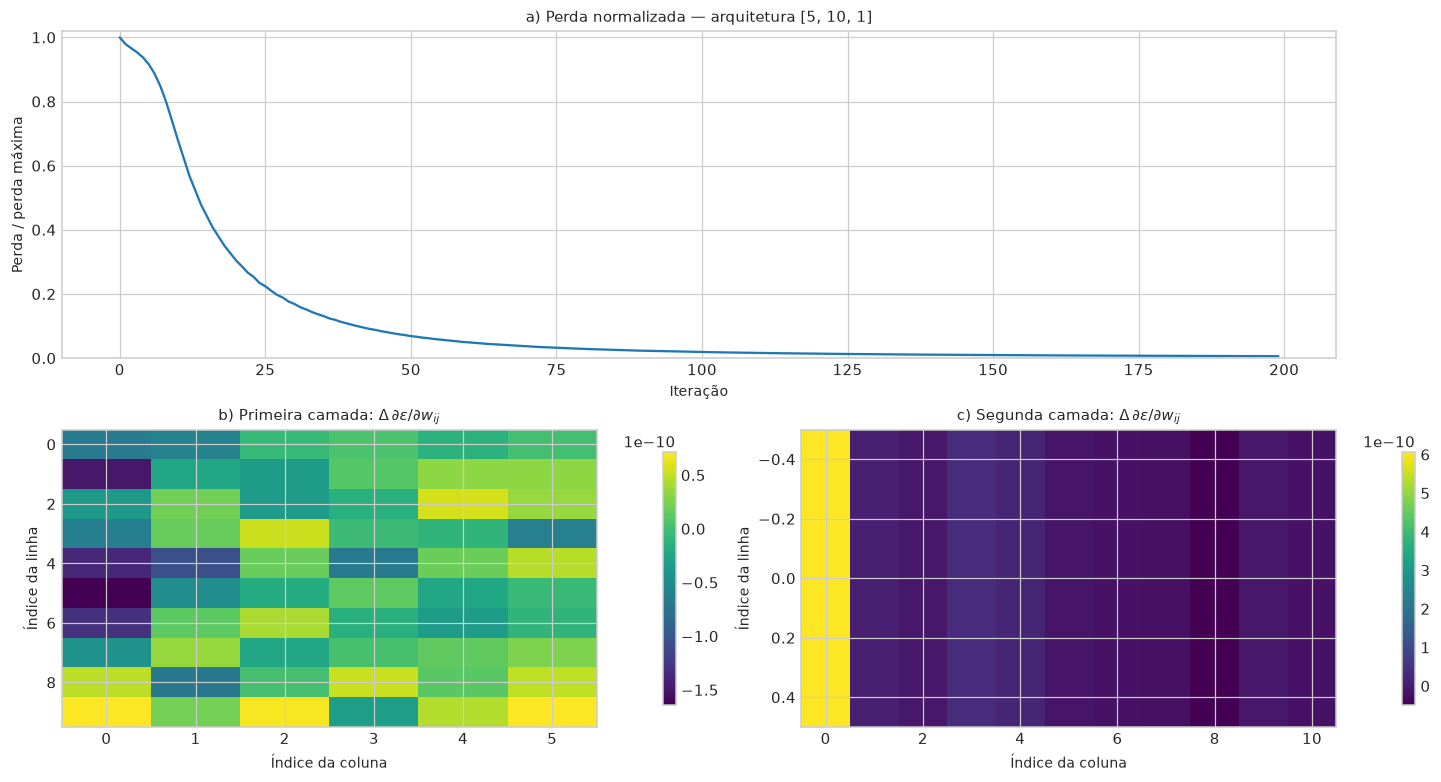

In [6]:
fig = plt.figure(figsize=(13, 7), constrained_layout=True)
grid = fig.add_gridspec(2, 2, height_ratios=[1.1, 1])

ax_loss = fig.add_subplot(grid[0, :])
normalized_loss = gradient_training.losses / gradient_training.losses.max()
ax_loss.plot(normalized_loss, color="tab:blue")
ax_loss.set(title="a) Perda normalizada — arquitetura [5, 10, 1]", xlabel="Iteração", ylabel="Perda / perda máxima", ylim=(0, 1.02))

titles = [
    r"b) Primeira camada: $\Delta\,\partial\epsilon/\partial w_{ij}$",
    r"c) Segunda camada: $\Delta\,\partial\epsilon/\partial w_{ij}$",
]
for column, (difference, title) in enumerate(zip(check["normalized_differences"], titles)):
    ax = fig.add_subplot(grid[1, column])
    image = ax.imshow(difference, cmap="viridis", aspect="auto")
    ax.set(title=title, xlabel="Índice da coluna", ylabel="Índice da linha")
    fig.colorbar(image, ax=ax, shrink=0.85)

plt.show()

### Discussão da validação

A validação apresenta um erro absoluto máximo de aproximadamente $2{,}53\times10^{-11}$ e erro relativo global de $9{,}97\times10^{-11}$. Esses valores são muito pequenos para a aproximação por diferenças centrais com $h=10^{-4}$ e mostram que duas formas independentes de obter as derivadas — retropropagação analítica e perturbação numérica de cada peso — produzem resultados praticamente idênticos no ponto testado. Portanto, o experimento fornece forte evidência de que o gradiente foi implementado corretamente. Porém, ele **não** demonstra, por si só, que o treinamento convergiu para um mínimo local.

Os mapas das Figuras b) e c) incluem todos os 71 parâmetros da rede: 60 elementos de $W^{[1]}\in\mathbb{R}^{10\times6}$ e 11 de $W^{[2]}\in\mathbb{R}^{1\times11}$, incluindo os bias. A escala das barras de cores, da ordem de $10^{-10}$, indica que a diferença normalizada permanece pequena nas duas camadas. A ausência de uma região com erros de magnitude claramente superior também sugere que não há falha sistemática associada a uma camada, linha ou coluna específica — comportamento que seria esperado em erros de transposição, propagação pela regra da cadeia, tratamento do bias ou indexação.

A curva da Figura a) responde a uma questão diferente. A perda normalizada diminui monotonicamente durante as 200 iterações e se aproxima de zero, mostrando que a direção fornecida pelo gradiente, combinada com a busca de passo, é efetiva para reduzir a função objetivo neste conjunto de treinamento. Ainda assim, uma curva decrescente não prova que o ponto final seja um mínimo local ou global. Para sustentar uma afirmação de convergência seria necessário examinar, por exemplo, a norma do gradiente final, o critério de parada e o comportamento sob diferentes inicializações.

O teste valida apenas a derivada da função efetivamente implementada e apenas na vizinhança dos pesos avaliados. Ele não verifica se os dados e rótulos estão corretos, se a função objetivo representa adequadamente o problema nem se as previsões generalizam para novos exemplos. Além disso, a ReLU não é diferenciável em $z=0$: se uma perturbação numérica atravessasse esse ponto, a diferença finita poderia discordar do gradiente adotado pelo código sem que isso caracterizasse necessariamente um erro de implementação. Neste teste, nenhuma unidade foi colocada nessa situação, permitindo uma comparação estável.

## 3. Classificação multiclasse

Agora a classe é a quantidade de bits iguais a 1. Portanto, existem seis classes, de 0 a 5, codificadas em vetores *one-hot*. São gerados 50 exemplos de cada classe, totalizando 300. A saída softmax transforma os seis logits em probabilidades que somam 1, e a classe prevista é o índice de maior probabilidade.

A arquitetura `[5, 1, 6]` é a do exemplo do livro: cinco entradas, um neurônio oculto e seis saídas. O treinamento usa gradientes conjugados, equivalente conceitual do `fmincg` do MATLAB.

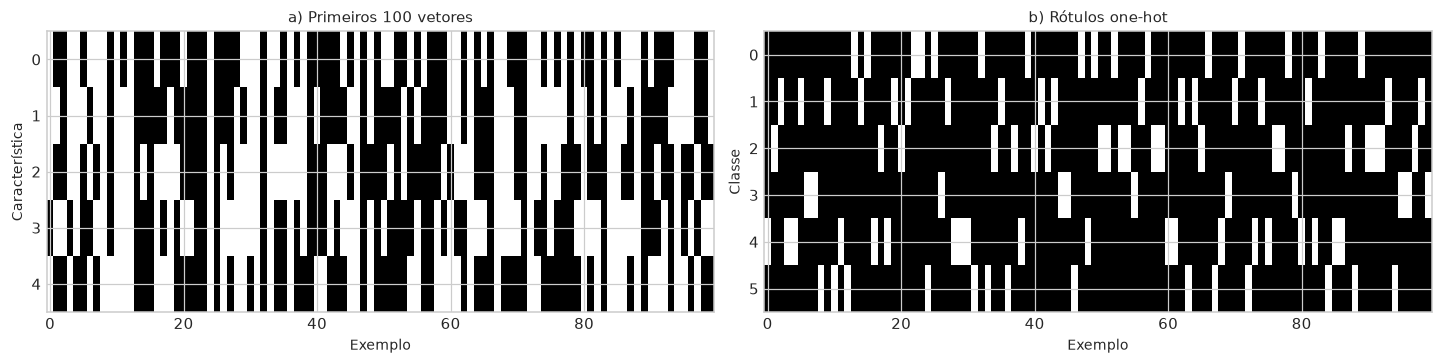

Exemplos por classe: [50 50 50 50 50 50]


In [7]:
x_multi, y_multi = generate_multiclass_data(seed=84)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.2), constrained_layout=True)
axes[0].imshow(x_multi[:, :100], cmap="gray", aspect="auto", interpolation="nearest", vmin=0, vmax=1)
axes[0].set(title="a) Primeiros 100 vetores", xlabel="Exemplo", ylabel="Característica")
axes[1].imshow(y_multi[:, :100], cmap="gray", aspect="auto", interpolation="nearest", vmin=0, vmax=1)
axes[1].set(title="b) Rótulos one-hot", xlabel="Exemplo", ylabel="Classe")
axes[1].set_yticks(range(6))
plt.show()

print("Exemplos por classe:", np.bincount(np.argmax(y_multi, axis=0)))

In [8]:
multiclass_results = {}
multiclass_rows = []
for activation_name in ["sigmoid", "elu"]:
    initial_weights = initialize_weights([5, 1, 6], seed=456)
    result = train_conjugate_gradient(
        x_multi,
        y_multi,
        initial_weights,
        hidden_activation=activation_name,
        loss_name="l2",
        n_iterations=200,
    )
    probability = predict(x_multi, result.weights, activation_name, "softmax")
    multiclass_results[activation_name] = (result, probability)
    multiclass_rows.append(
        {
            "Ativação oculta": activation_name.upper(),
            "Iterações registradas": len(result.losses),
            "Perda inicial registrada": result.losses[0],
            "Perda final": result.losses[-1],
            "Acurácia": multiclass_accuracy(y_multi, probability),
        }
    )

pd.DataFrame(multiclass_rows)

,Ativação oculta,Iterações registradas,Perda inicial registrada,Perda final,Acurácia
0,SIGMOID,200,0.833262,0.0823097,1
1,ELU,200,0.831934,0.000487124,1


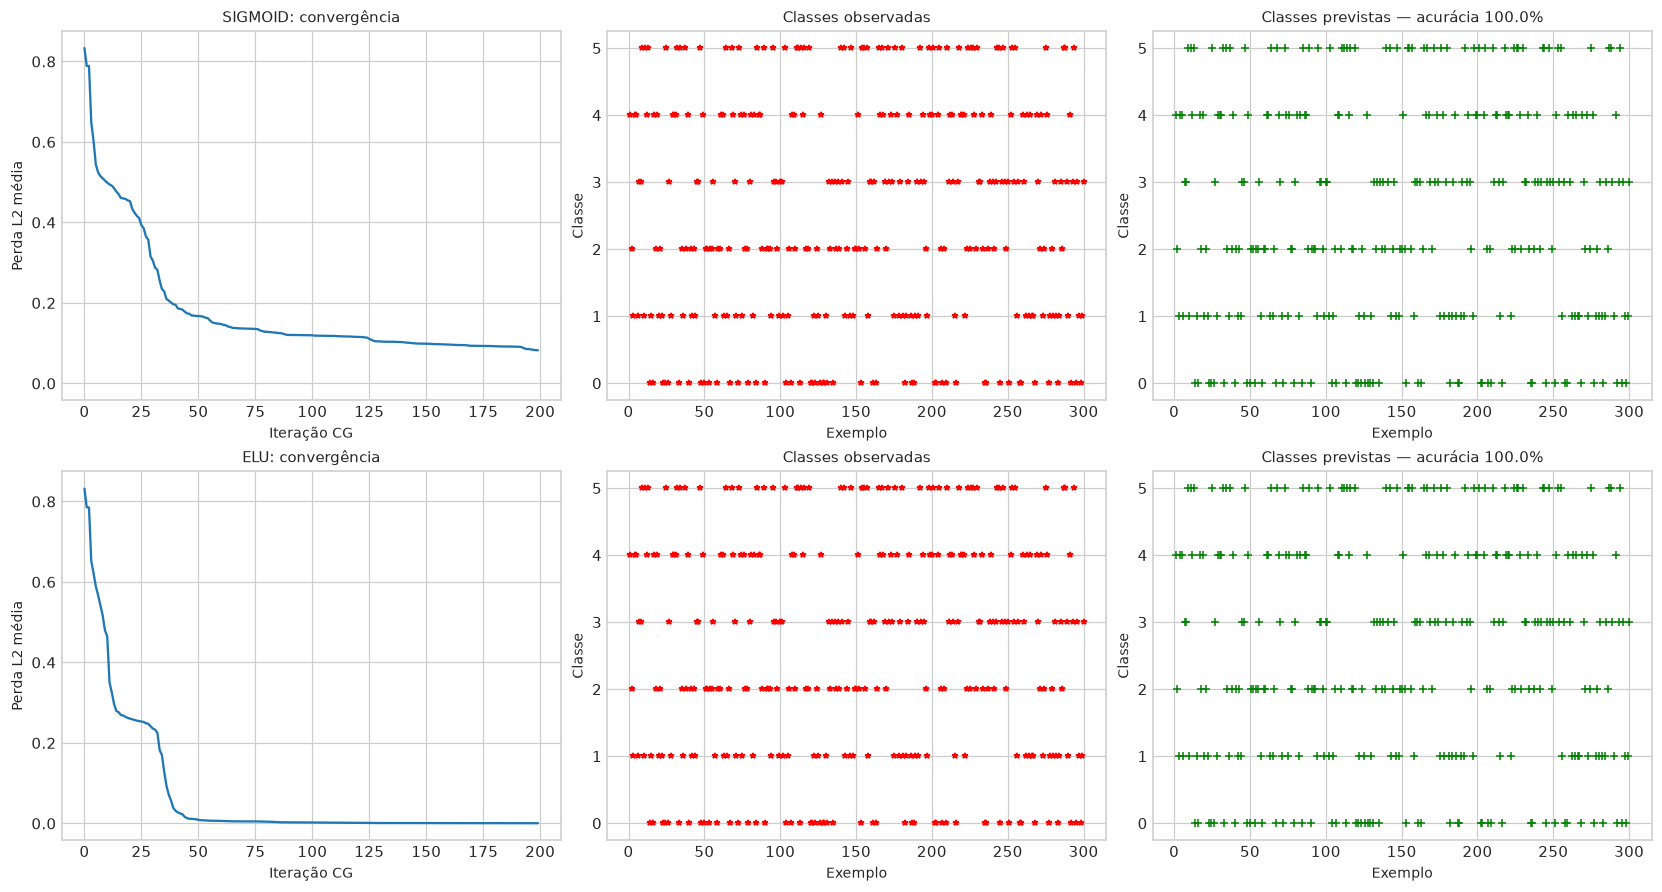

In [9]:
observed_class = np.argmax(y_multi, axis=0)
examples_multi = np.arange(1, observed_class.size + 1)
fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True, sharey="col")

for row, activation_name in enumerate(["sigmoid", "elu"]):
    result, probability = multiclass_results[activation_name]
    predicted_class = np.argmax(probability, axis=0)
    accuracy = np.mean(predicted_class == observed_class)

    axes[row, 0].plot(result.losses, color="tab:blue")
    axes[row, 0].set(title=f"{activation_name.upper()}: convergência", xlabel="Iteração CG", ylabel="Perda L2 média")
    axes[row, 1].plot(examples_multi, observed_class, "r*", markersize=4)
    axes[row, 1].set(title="Classes observadas", xlabel="Exemplo", ylabel="Classe")
    axes[row, 2].plot(examples_multi, predicted_class, "g+", markersize=5)
    axes[row, 2].set(title=f"Classes previstas — acurácia {accuracy:.1%}", xlabel="Exemplo", ylabel="Classe")

plt.show()

### Discussão dos resultados multiclasse

As redes com ativação sigmoide e ELU atingiram 100% de acurácia. Embora a arquitetura `[5, 1, 6]` seja bem rasa, ela é suficiente para este problema porque o rótulo não depende da posição dos bits, apenas da contagem $s=x_1+\cdots+x_5$. Assim, o neurônio oculto pode condensar as cinco entradas em uma representação escalar e monotônica de $s$. Na camada de saída, os seis logits são funções dessa única variável; a operação `argmax` separa o eixo em seis regiões de decisão ordenadas, uma para cada valor $s\in\{0,1,\ldots,5\}$.

A igualdade na acurácia não significa que as duas soluções sejam equivalentes. Após 200 iterações, a perda L2 com sigmoide é aproximadamente `0,0823`, enquanto com ELU cai para cerca de `0,000487`, uma redução de aproximadamente 169 vezes. Como a classe é determinada apenas pelo maior componente da saída softmax, previsões pouco separadas ainda podem produzir 100% de acertos. A perda muito menor da ELU indica que ela atribui probabilidades mais concentradas à classe correta e mantém maior margem em relação às demais classes.

A diferença de convergência é coerente com as derivadas das ativações. A sigmoide satura para valores de grande magnitude, reduzindo o gradiente que chega à primeira camada. A ELU é linear para entradas positivas e conserva derivada não nula também na região negativa; consequentemente, tende a fornecer direções de atualização mais informativas ao método de gradientes conjugados. Neste experimento, isso acelera a redução da perda, ainda que as duas redes já tenham encontrado as fronteiras de decisão corretas.

O conjunto gerado contém os 32 vetores possíveis de cinco bits, apesar de possuir 300 amostras por causa das repetições. Portanto, os 100% de acurácia confirmam que a regra foi aprendida em todo o domínio binário definido pelo experimento, e não apenas em uma pequena seleção de combinações. Ainda assim, o resultado não demonstra robustez a entradas contínuas, bits corrompidos, rótulos incorretos ou dados fora desse domínio; essas propriedades exigiriam experimentos específicos com ruído e perturbações.

Um ponto importante que notei e que acho válido comentar é que existe uma inconsistência relevante no material original: a opção 2 do `activation.m` é apresentada pela interface e pelas legendas como ReLU, mas sua expressão para $z<0$ é $e^z-1$, que corresponde à ELU com $\alpha=1$. Por isso, os resultados desta seção são identificados como ELU. Essa distinção é necessária para não atribuir à ReLU um comportamento produzido por outra função de ativação.

## Conclusões

1. A classificação binária é simples e linearmente separável; todas as quatro configurações atingem 100% no conjunto de treinamento, embora entropia cruzada e ReLU levem a saídas mais confiantes e à menor perda.
2. O teste por diferenças centrais confirma o gradiente analítico com erro relativo próximo de $10^{-10}$, validando a retropropagação nas duas camadas.
3. A rede multiclasse `[5, 1, 6]` aprende as seis contagens possíveis; ELU converge mais rapidamente que sigmoide no orçamento fixado.
4. Os experimentos reproduzem o objetivo didático das figuras, mas não incluem conjunto de validação/teste. Uma avaliação de generalização exigiria separar dados inéditos e, idealmente, repetir o treinamento com várias sementes.

Todas as figuras e tabelas acima são produzidas pelas células do próprio notebook; basta executar **Run All** para regenerá-las.